# Notebook 6: QED Stratification & Held-Out Reward-Hacking Audit

### Objectives
1. Examine QED-stratified performance across initial headroom bins (Low, Medium, High, Very High).
2. Audit against reward-hacking using held-out filters: Lipinski Rule of 5, PAINS alerts, Brenk alerts, and structural sanity.

In [1]:
import torch
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root_dir = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

strat_path = os.path.join(root_dir, 'results', 'qed_stratified_summary.csv')
df_strat = pd.read_csv(strat_path)
print('=== QED-Stratified Results by Starting Headroom ===')
display(df_strat)

=== QED-Stratified Results by Starting Headroom ===


,method,qed_group,delta_qed,delta_qed.1,nhg,success,similarity,final_sas,num_edits
0,NaN,NaN,mean,std,mean,mean,mean,mean,mean
1,Greedy Hill Climbing,High (0.7-0.85),0.07950353614050289,0.04012794032343191,0.40193541764213636,0.42857142857142855,0.5781726044590266,3.3028725092435893,2.142857142857143
2,Greedy Hill Climbing,Low (<0.5),0.19898955733754642,0.07643553272021755,0.34941415836067874,1.0,0.6353508019630684,3.549251842860093,1.0714285714285714
3,Greedy Hill Climbing,Medium (0.5-0.7),0.1251428950752283,0.05046081140163303,0.3268420879709225,0.875,0.590705118212702,3.7242025540881474,1.6875
4,Greedy Hill Climbing,Very High (>=0.85),0.04195021160676446,0.02619905167738495,0.341245856905351,0.0,0.5931652953891904,3.1538287470480917,2.125
5,PPO Adaptive (Proposed),High (0.7-0.85),-0.1461363161901224,0.12023061433575433,-0.7436624006062156,0.0,0.48202792402416833,3.9168174447920294,10.0
6,PPO Adaptive (Proposed),Low (<0.5),-0.07177838140349421,0.13254908252352487,-0.1291102387985918,0.14285714285714285,0.5251275798530368,3.60135431811466,9.0
7,PPO Adaptive (Proposed),Medium (0.5-0.7),-0.16685124199918894,0.1641954841825571,-0.4272848237847737,0.0625,0.470765536416607,3.911916316110491,9.4375
8,PPO Adaptive (Proposed),Very High (>=0.85),-0.19650500512288668,0.21950218737321336,-1.7840180878621166,0.0,0.5008560406455861,3.5953537195561323,10.0
9,PPO Baseline,High (0.7-0.85),-0.5271371324771734,0.15226148710598228,-2.7212252240955928,0.0,0.2523926421157156,4.654239395952563,10.0


### 1. Starting Headroom Comparison Chart
Shows how Adaptive reward shaping avoids saturation on high-QED molecules.

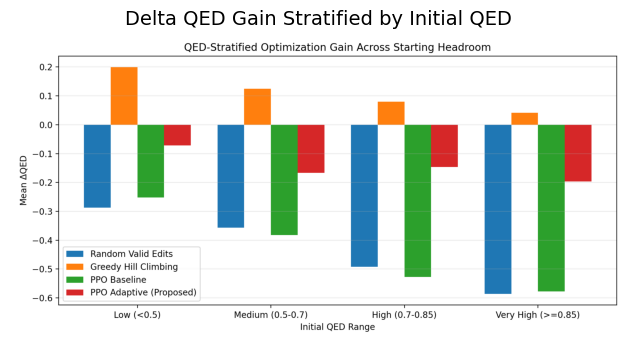

In [2]:
fig_strat = os.path.join(root_dir, 'figures', 'qed_stratified_comparison.png')
if os.path.exists(fig_strat):
    img = Image.open(fig_strat)
    plt.figure(figsize=(10, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Delta QED Gain Stratified by Initial QED', fontsize=14)
    plt.show()

### 2. Reward-Hacking Audit Table & Chart
Evaluates whether policies generate structural alerts or un-druglike motifs.

=== Structural Alert & Druglikeness Audit ===


,method,pains_alert,brenk_alert,lipinski_violations,sanity_passed,valid
0,Greedy Hill Climbing,0.066667,0.250000,0.033333,1.0,1.0
1,PPO Adaptive (Proposed),0.033333,0.650000,0.166667,1.0,1.0
2,PPO Baseline,0.166667,0.983333,0.783333,1.0,1.0
3,Random Valid Edits,0.183333,0.983333,0.716667,1.0,1.0


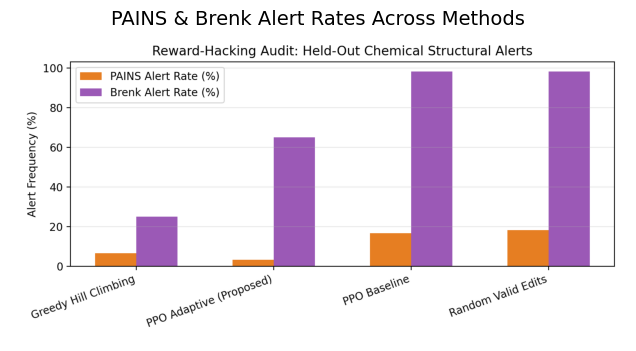

In [3]:
audit_path = os.path.join(root_dir, 'results', 'reward_hacking_audit.csv')
df_audit = pd.read_csv(audit_path)
print('=== Structural Alert & Druglikeness Audit ===')
display(df_audit)

fig_audit = os.path.join(root_dir, 'figures', 'reward_hacking_audit_chart.png')
if os.path.exists(fig_audit):
    img = Image.open(fig_audit)
    plt.figure(figsize=(10, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.title('PAINS & Brenk Alert Rates Across Methods', fontsize=14)
    plt.show()